In [3]:
import pandas as pd
from sqlalchemy import create_engine

# Создаем базу данных
engine = create_engine('sqlite:///../superstore.db')

# Загружаем очищенные данные
df_cleaned = pd.read_csv('../data/cleaned_data.csv')

# Отправляем в SQL
df_cleaned.to_sql('orders', engine, if_exists='replace', index=False)
print("✅ Данные загружены в SQL!")

✅ Данные загружены в SQL!


In [2]:
!pip install sqlalchemy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 2.9 MB/s  0:00:01 eta 0:00:01

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [4]:
# Запрос: Выручка и прибыль по категориям товаров
query_1 = """
SELECT 
    Category, 
    SUM(Sales) AS total_sales,
    SUM(Profit) AS total_profit
FROM orders
GROUP BY Category
ORDER BY total_sales DESC;
"""

sales_by_category = pd.read_sql_query(query_1, engine)
print(sales_by_category)

          Category  total_sales  total_profit
0       Technology  836154.0330   145454.9481
1        Furniture  741306.3133    18421.8137
2  Office Supplies  718735.2440   122364.6608


In [5]:
query_2 = """
SELECT 
    State, 
    SUM(Sales) AS total_sales
FROM orders
GROUP BY State
ORDER BY total_sales DESC
LIMIT 5;
"""
top_states = pd.read_sql_query(query_2, engine)
print(top_states)

          State  total_sales
0    California  457576.2715
1      New York  310827.1510
2         Texas  170124.5418
3    Washington  138560.8100
4  Pennsylvania  116496.3620


In [6]:
query_3 = """
SELECT 
    Category,
    ROUND(AVG(Discount) * 100, 2) AS avg_discount_percent,
    ROUND(AVG(Profit), 2) AS avg_profit
FROM orders
GROUP BY Category;
"""
discount_impact = pd.read_sql_query(query_3, engine)
print(discount_impact)

          Category  avg_discount_percent  avg_profit
0        Furniture                 17.40        8.70
1  Office Supplies                 15.74       20.35
2       Technology                 13.23       78.75


/tmp/ipykernel_7702/4282515052.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Category', y='total_sales', data=sales_by_category, palette='viridis')


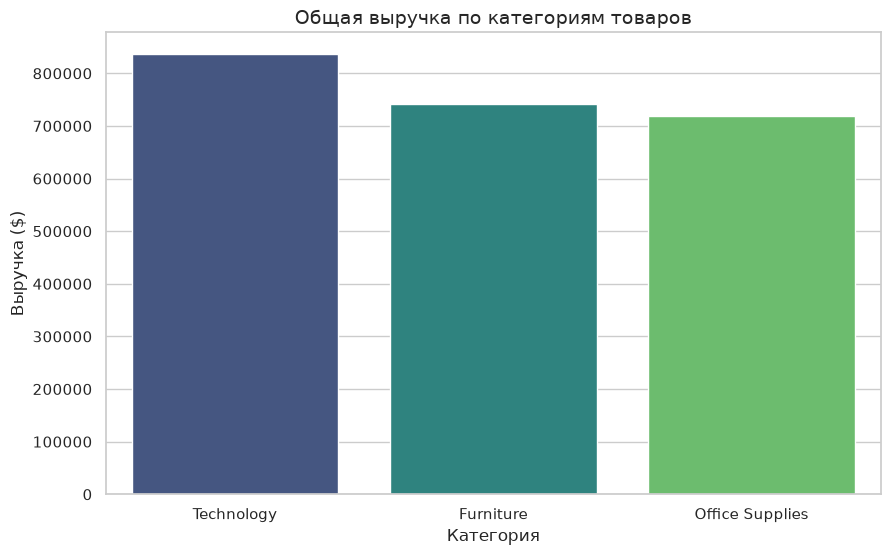

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Настраиваем стиль графиков
sns.set_theme(style="whitegrid")

# Строим график
plt.figure(figsize=(10, 6))
sns.barplot(x='Category', y='total_sales', data=sales_by_category, palette='viridis')

# Добавляем подписи
plt.title('Общая выручка по категориям товаров', fontsize=14)
plt.xlabel('Категория', fontsize=12)
plt.ylabel('Выручка ($)', fontsize=12)

# Сохраняем график в папку outputs
plt.savefig('../outputs/sales_by_category.png', bbox_inches='tight')
plt.show()

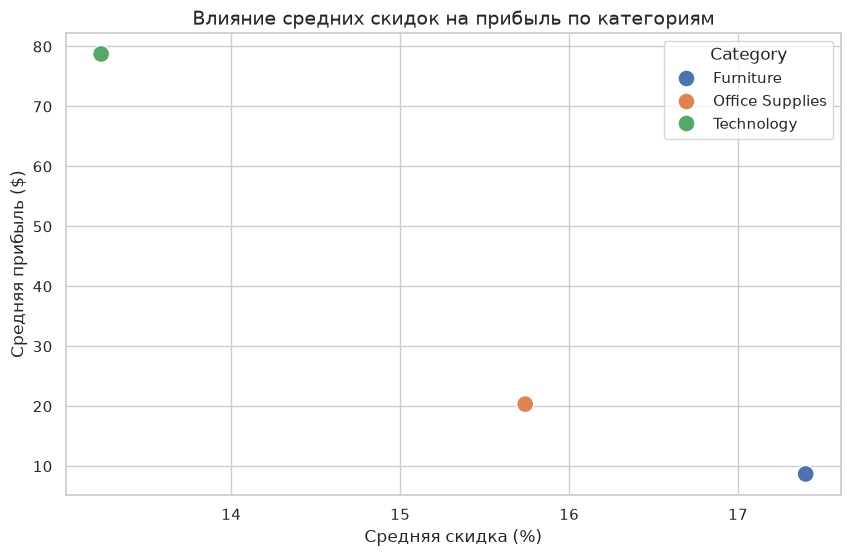

In [12]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='avg_discount_percent', y='avg_profit', hue='Category', data=discount_impact, s=150)

plt.title('Влияние средних скидок на прибыль по категориям', fontsize=14)
plt.xlabel('Средняя скидка (%)', fontsize=12)
plt.ylabel('Средняя прибыль ($)', fontsize=12)

# Сохраняем график
plt.savefig('../outputs/discount_vs_profit.png', bbox_inches='tight')
plt.show()

 Основные выводы и рекомендации

На основе анализа данных и визуализации были сделаны следующие выводы:

1. Лидер по выручке: Категория Technology приносит наибольшую общую выручку (более 800 тыс. $), опережая Furniture и Office Supplies.
2. Влияние скидок на маржинальность: Прослеживается четкая обратная зависимость между размером скидки и чистой прибылью. 
    * Самая прибыльная категория — Technology*(средняя прибыль ~80$ при скидке ~14%).
    * Самая проблемная категория — Furniture (средняя прибыль менее 10$ при максимальной скидке ~17.5%)
💡 Бизнес-рекомендация:
Необходимо пересмотреть политику скидок в категории Furniture. Текущий уровень скидок (около 17.5%) практически обнуляет прибыль от продаж мебели. Рекомендуется снизить максимальный размер скидки в этой категории до 10-12% для повышения маржинальности.

In [10]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [8]:
!pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 2.4 MB/s  0:00:04m0:00:0100:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 766.1 kB/s  0:00:06 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 1.1 MB/s  0:00:01 eta 0:00:010m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 815.0 kB/s  0:00:08 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
